# 5.3 Интегрирование методом Монте-Карло

# 5.3 蒙特卡洛积分

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (8, 4), "font.size": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.prop_cycle": plt.cycler(color=["#356AE6", "#D55E00", "#009E73"]),
    "figure.dpi": 110,
})
from scipy.special import erf

## Одномерный интеграл
Для $x_i\sim U(a,b)$ используем $I_{MC}=(b-a)\operatorname{mean}(f(x_i))$. Здесь $f(x)=e^{-x^2}$ и $[a,b]=[0,1]$.

## 一维积分
当 $x_i\sim U(a,b)$ 时，使用 $I_{MC}=(b-a)\operatorname{mean}(f(x_i))$。这里 $f(x)=e^{-x^2}$，区间为 $[0,1]$。

In [2]:
rng = np.random.default_rng(42)
N = 100_000
a, b = 0.0, 1.0
x = rng.uniform(a, b, N)
f = np.exp(-x**2)
I_mc = (b - a) * f.mean()
SE = (b - a) * f.std(ddof=1) / np.sqrt(N)
I_exact = np.sqrt(np.pi) * erf(1) / 2
print(f"I_MC = {I_mc:.8f}")
print(f"SE   = {SE:.8f}")
print(f"I_ref = {I_exact:.8f}")

I_MC = 0.74639593
SE   = 0.00063516
I_ref = 0.74682413


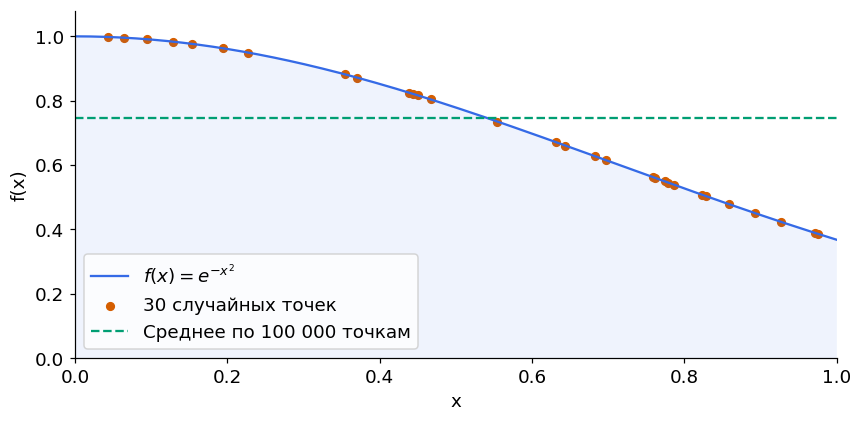

In [3]:
grid = np.linspace(a, b, 300)
fig, ax = plt.subplots()
ax.plot(grid, np.exp(-grid**2), label=r"$f(x)=e^{-x^2}$")
ax.scatter(x[:30], f[:30], color="#D55E00", s=25, label="30 случайных точек")
ax.axhline(f.mean(), color="#009E73", linestyle="--", label="Среднее по 100 000 точкам")
ax.fill_between(grid, np.exp(-grid**2), alpha=0.08)
ax.set(xlabel="x", ylabel="f(x)", xlim=(0, 1), ylim=(0, 1.08))
ax.legend(loc="lower left")
fig.tight_layout()
plt.show()

## Повторные оценки и интервалы
Двадцать независимых опытов по 10 000 точек. Полосы показывают $I_{MC}\pm1.96SE$. Эталон получен через функцию ошибок `erf`.

## 重复估计与区间
进行 20 次独立试验，每次 10 000 点。误差棒表示 $I_{MC}\pm1.96SE$。参考值通过误差函数 `erf` 得到。

Интервалы с эталоном / 包含参考值的区间: 19/20


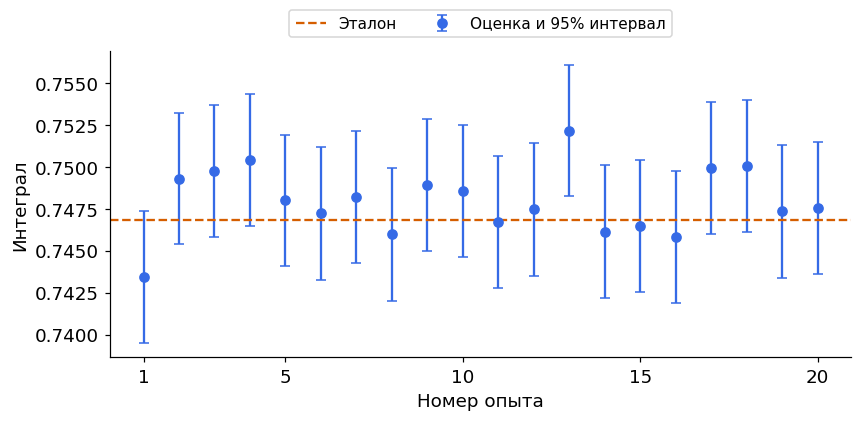

In [4]:
rng_intervals = np.random.default_rng(2026)
R, N_repeat = 20, 10_000
values = np.exp(-rng_intervals.random((R, N_repeat))**2)
integrals = values.mean(axis=1)
standard_errors = values.std(axis=1, ddof=1) / np.sqrt(N_repeat)
covered = np.abs(integrals - I_exact) <= 1.96 * standard_errors
print(f"Интервалы с эталоном / 包含参考值的区间: {covered.sum()}/{R}")
fig, ax = plt.subplots()
ax.errorbar(np.arange(1, R + 1), integrals, yerr=1.96 * standard_errors,
            fmt="o", capsize=3, label="Оценка и 95% интервал")
ax.axhline(I_exact, color="#D55E00", linestyle="--", label="Эталон")
ax.set(xlabel="Номер опыта", ylabel="Интеграл", xticks=[1, 5, 10, 15, 20])
ax.ticklabel_format(axis="y", style="plain", useOffset=False)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=2, fontsize=10)
fig.tight_layout()
plt.show()

## Шесть измерений
В каждой строке массива `x6` лежит одна точка из $[0,1]^6$. `axis=1` суммирует квадраты шести координат. Объём области равен 1.

## 六维积分
数组 `x6` 的每一行是 $[0,1]^6$ 中的一个采样点。`axis=1` 对每个点的六个坐标平方求和。积分区域体积为 1。

In [5]:
rng6 = np.random.default_rng(42)
N6, d = 200_000, 6
x6 = rng6.random((N6, d))
f6 = np.exp(-np.sum(x6**2, axis=1))
I6_mc = f6.mean()
SE6 = f6.std(ddof=1) / np.sqrt(N6)
I6_exact = I_exact**d
print("x6.shape:", x6.shape, "f6.shape:", f6.shape)
print(f"I6_MC = {I6_mc:.8f}, SE = {SE6:.8f}")
print(f"I6_ref = {I6_exact:.8f}")

x6.shape: (200000, 6) f6.shape: (200000,)
I6_MC = 0.17359944, SE = 0.00028016
I6_ref = 0.17350423


## Размерность и относительная ошибка
У этого примера интеграл разделяется в произведение одномерных интегралов, поэтому есть эталон. Проверим размерности 1–10 при одинаковом числе точек. Показатель $N^{-1/2}$ не зависит от размерности, но относительная ошибка и стоимость вычисления могут расти.

## 维数与相对误差
本例积分可以分解为一维积分的乘积，因此有参考值。在相同采样点数下比较 1–10 维。$N^{-1/2}$ 的指数不依赖维数，但相对误差和计算成本可能随维数增加。

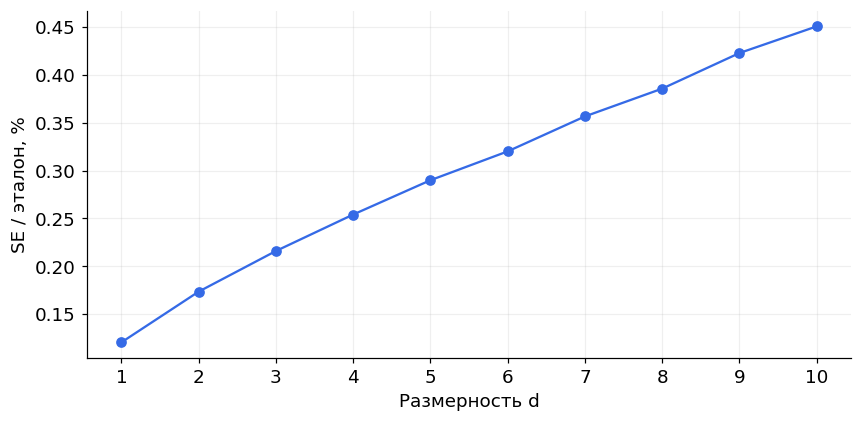

In [6]:
rng_dims = np.random.default_rng(2027)
dimensions = np.arange(1, 11)
N_dim = 50_000
relative_se = []
for dim in dimensions:
    points = rng_dims.random((N_dim, dim))
    values_dim = np.exp(-np.sum(points**2, axis=1))
    se_dim = values_dim.std(ddof=1) / np.sqrt(N_dim)
    relative_se.append(se_dim / I_exact**dim)
relative_se = np.array(relative_se)
fig, ax = plt.subplots()
ax.plot(dimensions, 100 * relative_se, "o-")
ax.set(xlabel="Размерность d", ylabel="SE / эталон, %", xticks=dimensions)
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

## Попробуйте
Увеличьте $N6$ в четыре раза и сравните SE. Для одномерного гладкого интеграла также сравните стоимость с квадратурой из третьей лекции.

## 练习
把 $N6$ 增大至四倍并比较 SE。对于一维光滑函数积分，再与第三讲中的数值求积比较计算成本。